---
title: "Gaussian, Gamma and Quantum-Statistics Integrals"
short_title: "T-M2 Gaussian & Gamma Integrals"
numbering:
  heading_2: true
  equation: true
---

# Gaussian, Gamma and Quantum-Statistics Integrals

:::{tip} Where this sits in the plan
Math for **kinetic theory** (topic 1), **Boltzmann statistics** (topic 6) and **quantum statistics** (topic 7). Nearly every integral in the thermo book is one of three families: Gaussians, Gamma functions, or the Bose and Fermi integrals.

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Gaussian integrals | 15 (polar) | 11 | – | 13 |
| Gamma function | – | 11 | – | 13 |
| Multiple integrals and Jacobians | 15 | 5 | 9 | 3 |
| Riemann zeta function | – | – | – | 12, 13 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate hint and answer dropdowns.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [T-M1: Counting, probability and Stirling's approximation](01-counting-probability-stirling.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **The Gaussian Integral**

   (a) Evaluate $\int_{-\infty}^{\infty}e^{-3x^2}\,dx$.

   (b) Find $\int_{-\infty}^{\infty}x^2e^{-ax^2}\,dx$ by differentiating with respect to $a$.

   (c) Evaluate $\int_{-\infty}^{\infty}e^{-x^2 + 2x}\,dx$ by completing the square.

   (d) Evaluate $\int_0^\infty xe^{-ax^2}\,dx$.

2. **The Gamma Function**

   (a) Find $\Gamma(5)$ and $\Gamma(5/2)$.

   (b) Evaluate $\int_0^\infty x^4e^{-x^2}\,dx$ and $\int_0^\infty x^3e^{-2x}\,dx$.

   (c) Find the most probable speed in the Maxwell distribution, $f(v) \propto v^2e^{-mv^2/2kT}$.

3. **Volumes of Spheres in Many Dimensions**

   With $V_d(r) = \dfrac{\pi^{d/2}r^d}{\Gamma(d/2 + 1)}$:

   (a) Check that $d = 3$ gives $\tfrac43\pi r^3$.

   (b) How is the surface area of a $d$-ball related to its volume? Check it for $d = 2$.

   (c) What fraction of a 100-dimensional ball's volume lies in its outer 1% shell?

4. **Bose and Fermi Integrals**

   Using $\int_0^\infty\dfrac{x^{s-1}}{e^x - 1}\,dx = \Gamma(s)\zeta(s)$, with $\zeta(2) = \pi^2/6$ and $\zeta(4) = \pi^4/90$:

   (a) Evaluate $\int_0^\infty\dfrac{x}{e^x - 1}\,dx$ and $\int_0^\infty\dfrac{x^3}{e^x - 1}\,dx$.

   (b) Evaluate $\int_0^\infty\dfrac{x}{e^x + 1}\,dx$.

:::{dropdown} Answers
1. (a) $\sqrt{\pi/3}$.

   (b) $\dfrac{\sqrt\pi}{2}a^{-3/2}$.

   (c) $e\sqrt\pi$.

   (d) $\dfrac{1}{2a}$.

2. (a) $\Gamma(5) = 24$ and $\Gamma(5/2) = \tfrac34\sqrt\pi$.

   (b) $\Gamma(5/2)/2 = \tfrac38\sqrt\pi$, and $3!/2^4 = \tfrac38$.

   (c) $v_{\text{mp}} = \sqrt{2kT/m}$.

3. (a) $\pi^{3/2}r^3/\Gamma(5/2) = \pi^{3/2}r^3/\left(\tfrac34\sqrt\pi\right) = \tfrac43\pi r^3$.

   (b) $A_d = dV_d/dr$. For $d = 2$, $d(\pi r^2)/dr = 2\pi r$.

   (c) $1 - 0.99^{100} \approx 0.63$.

4. (a) $\Gamma(2)\zeta(2) = \pi^2/6$, and $\Gamma(4)\zeta(4) = \pi^4/15$.

   (b) $\left(1 - 2^{-1}\right)\pi^2/6 = \pi^2/12$.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
k_B = 1.380649e-23     # J/K
N_A = 6.02214e23       # 1/mol
R_gas = k_B * N_A      # J/(mol K)
h = 6.62607e-34        # J s
hbar = h / (2 * np.pi)
eV = 1.602177e-19      # J
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## The Gaussian Integral

$$
\int_{-\infty}^{\infty}e^{-ax^2}\,dx = \sqrt{\frac{\pi}{a}}\qquad(a > 0) .
$$ (eq-gaussian)

There is no antiderivative in elementary functions, but squaring the integral and switching to polar coordinates makes it easy.

:::{prf:proof} Proof by squaring
:class: dropdown

Call the integral $I$. Then

$$
I^2 = \int\!\!\int e^{-a(x^2 + y^2)}\,dx\,dy = \int_0^{2\pi}\!\!\int_0^\infty e^{-ar^2}\,r\,dr\,d\phi = 2\pi\cdot\frac{1}{2a} = \frac{\pi}{a} .
$$

The Jacobian factor $r$ from $dx\,dy = r\,dr\,d\phi$ is what makes the radial integral elementary.
:::

### Moments by differentiating under the integral

Differentiate {eq}`eq-gaussian` with respect to $a$; each derivative brings down $-x^2$:

$$
\int_{-\infty}^\infty x^2e^{-ax^2}\,dx = -\frac{d}{da}\sqrt{\frac\pi a} = \frac12\sqrt{\frac{\pi}{a^3}},
\qquad
\int_{-\infty}^\infty x^4e^{-ax^2}\,dx = \frac34\sqrt{\frac{\pi}{a^5}} .
$$ (eq-gaussian-moments)

Odd moments vanish by symmetry. Over a half-line, the even ones are halved, and the odd ones are elementary: $\int_0^\infty xe^{-ax^2}dx = 1/2a$, then differentiate for $x^3$, $x^5$, ...

**Completing the square** handles a linear term:

$$
\int_{-\infty}^\infty e^{-ax^2 + bx}\,dx = \sqrt{\frac\pi a}\,e^{b^2/4a} .
$$ (eq-gaussian-shift)

(Shift $x\to x + b/2a$.) This is the Fourier transform of a Gaussian when $b = ik$, which appears again in the quantum book.

In [2]:
a, x = sp.symbols("a x", positive=True)
for n in [0, 2, 4, 6]:
    I = sp.integrate(x**n * sp.exp(-a * x**2), (x, -sp.oo, sp.oo))
    display(Math(rf"\int_{{-\infty}}^{{\infty}} x^{{{n}}}e^{{-ax^2}}\,dx = " + sp.latex(sp.simplify(I))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

## The Gamma Function

$$
\Gamma(z) = \int_0^\infty t^{z-1}e^{-t}\,dt\qquad(z > 0) .
$$ (eq-gamma)

Integration by parts gives $\Gamma(z + 1) = z\,\Gamma(z)$, and $\Gamma(1) = 1$, so for integers $\Gamma(n + 1) = n!$. The Gamma function is the factorial extended to non-integers.

The key half-integer value comes from the Gaussian: substitute $t = x^2$ in $\Gamma(\tfrac12)$,

$$
\Gamma\!\left(\tfrac12\right) = \int_0^\infty t^{-1/2}e^{-t}\,dt = 2\int_0^\infty e^{-x^2}\,dx = \sqrt\pi .
$$

Then the recursion gives $\Gamma(\tfrac32) = \tfrac12\sqrt\pi$, $\Gamma(\tfrac52) = \tfrac34\sqrt\pi$, and so on.

**The workhorse formula.** With $t = ax^2$, any Gaussian moment over a half-line is a Gamma function:

$$
\int_0^\infty x^ne^{-ax^2}\,dx = \frac{\Gamma\!\left(\frac{n+1}{2}\right)}{2a^{(n+1)/2}} .
$$ (eq-gaussian-gamma)

And with $t = ax$, the exponential moments are $\int_0^\infty x^ne^{-ax}\,dx = n!/a^{n+1}$.

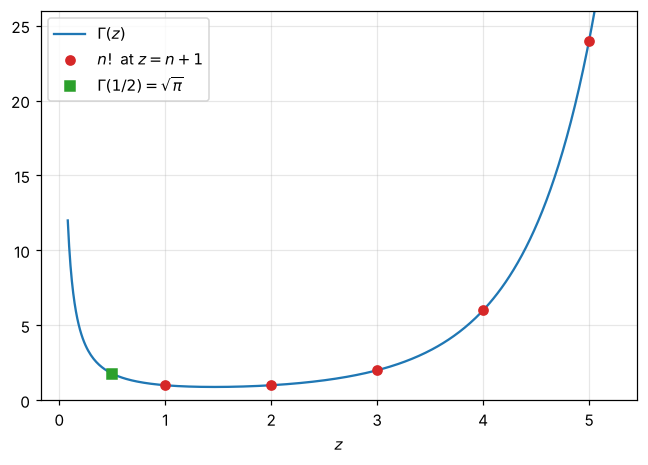

In [3]:
#| label: fig-gamma-function
#| caption: "The Gamma function on the positive axis, passing through the factorials Γ(n+1) = n! (dots) and through √π at z = 1/2. It has a minimum near z ≈ 1.46 and grows faster than any exponential."
from scipy.special import gamma, factorial
z = np.linspace(0.08, 5.2, 400)
fig, ax = plt.subplots()
ax.plot(z, gamma(z), label=r"$\Gamma(z)$")
n = np.arange(0, 5)
ax.plot(n + 1, factorial(n), "o", color="tab:red", label=r"$n!$ at $z = n+1$")
ax.plot(0.5, np.sqrt(np.pi), "s", color="tab:green", label=r"$\Gamma(1/2) = \sqrt{\pi}$")
ax.set_ylim(0, 26); ax.set_xlabel("$z$"); ax.legend(); plt.show()

::::{prf:example} The Maxwell speed distribution's normalization and mean speed
:label: ex-maxwell-integrals

In thermo topic 1, the distribution of molecular speeds is $D(v) = Cv^2e^{-mv^2/2kT}$. Find $C$ and the mean speed $\bar v$.

:::{dropdown} Solution
Write $a = m/2kT$. Normalization uses {eq}`eq-gaussian-gamma` with $n = 2$:

$$
1 = C\int_0^\infty v^2e^{-av^2}dv = C\frac{\Gamma(3/2)}{2a^{3/2}} = C\frac{\sqrt\pi}{4a^{3/2}}
\quad\Rightarrow\quad C = \frac{4a^{3/2}}{\sqrt\pi} = 4\pi\left(\frac{m}{2\pi kT}\right)^{3/2} .
$$

The mean speed uses $n = 3$: $\int_0^\infty v^3e^{-av^2}dv = \Gamma(2)/2a^2 = 1/2a^2$. So

$$
\bar v = C\cdot\frac{1}{2a^2} = \frac{2}{\sqrt{\pi a}} = \sqrt{\frac{8kT}{\pi m}} .
$$
:::
::::

## Volumes of Spheres in Many Dimensions

Counting quantum states of an ideal gas (thermo topic 6) needs the volume of a sphere in $d$ dimensions, where $d = 3N$ can be $10^{24}$. The Gaussian integral produces it cheaply.

:::{prf:theorem} Volume of a $d$-ball
:label: thm-d-ball

A ball of radius $r$ in $d$ dimensions has volume

$$
V_d(r) = \frac{\pi^{d/2}}{\Gamma\!\left(\frac d2 + 1\right)}\,r^d .
$$ (eq-d-ball)

Check: $d = 2$ gives $\pi r^2$, $d = 3$ gives $\pi^{3/2}r^3/\Gamma(5/2) = \tfrac43\pi r^3$.
:::

:::{prf:proof}
:class: dropdown

Compute $\int e^{-r^2}d^dx$ two ways. In Cartesian coordinates it is a product of $d$ one-dimensional Gaussians, $\pi^{d/2}$. In spherical shells, the shell of radius $r$ has area $S_d r^{d-1}$, so the integral is $S_d\int_0^\infty r^{d-1}e^{-r^2}dr = S_d\,\Gamma(d/2)/2$. Hence $S_d = 2\pi^{d/2}/\Gamma(d/2)$, and integrating the area from 0 to $r$ gives $V_d = S_dr^d/d = \pi^{d/2}r^d/\Gamma(d/2 + 1)$.
:::

For large $d$, almost all of the volume is in a thin shell near the surface: the fraction within radius $(1 - \epsilon)r$ is $(1-\epsilon)^d\approx e^{-d\epsilon}$. With $d = 3N$, "the states with energy *below* $U$" and "the states with energy *near* $U$" are the same count, to the accuracy that matters for $\ln\Omega$.

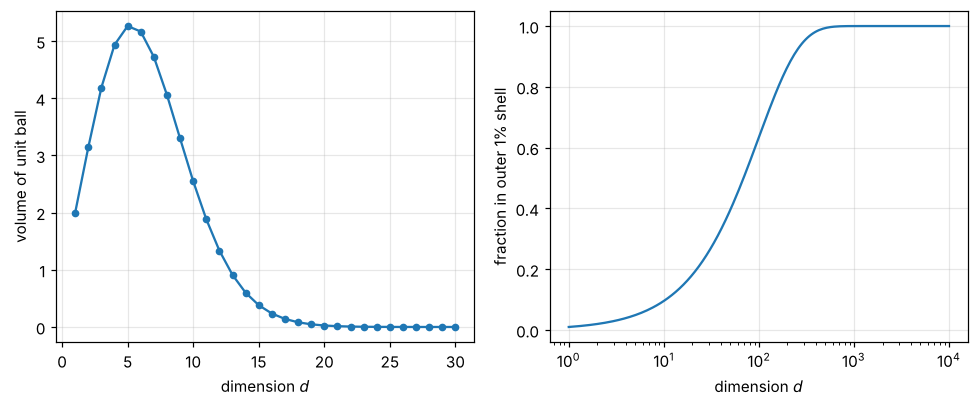

In [4]:
#| label: fig-d-ball
#| caption: "Left, the volume of the unit ball peaks at d = 5 and then collapses toward zero. Right, the fraction of a d-ball's volume in its outer 1% shell; by d = 1000 essentially all of it is there."
from scipy.special import gammaln
d = np.arange(1, 31)
Vd = np.exp((d / 2) * np.log(np.pi) - gammaln(d / 2 + 1))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.8))
ax1.plot(d, Vd, "o-", ms=4); ax1.set_xlabel("dimension $d$"); ax1.set_ylabel("volume of unit ball")
dd = np.logspace(0, 4, 200)
ax2.semilogx(dd, 1 - 0.99**dd); ax2.set_xlabel("dimension $d$"); ax2.set_ylabel("fraction in outer 1% shell")
plt.tight_layout(); plt.show()

## Bose and Fermi Integrals

Blackbody radiation, the Debye solid and Bose–Einstein condensation (thermo topic 7) all lead to integrals of the form

$$
\int_0^\infty\frac{x^{s-1}}{e^x - 1}\,dx = \Gamma(s)\,\zeta(s),
\qquad
\zeta(s) = \sum_{n=1}^\infty\frac{1}{n^s} .
$$ (eq-bose-integral)

:::{prf:proof} Expand the denominator as a geometric series
:class: dropdown

For $x > 0$, $\dfrac{1}{e^x - 1} = \dfrac{e^{-x}}{1 - e^{-x}} = \sum_{n=1}^\infty e^{-nx}$. Integrating term by term,

$$
\int_0^\infty x^{s-1}\sum_n e^{-nx}\,dx = \sum_n\frac{\Gamma(s)}{n^s} = \Gamma(s)\zeta(s) .
$$
:::

The values that appear most:

| $s$ | $\Gamma(s)\zeta(s)$ | where it shows up |
|---|---|---|
| 3/2 | $\tfrac{\sqrt\pi}{2}\times2.612$ | Bose–Einstein condensation temperature |
| 3 | $2\times1.202$ | photon number density |
| 4 | $6\times\pi^4/90 = \pi^4/15$ | Stefan–Boltzmann law |

For fermions the sign in the denominator flips, and alternating signs make $\int_0^\infty x^{s-1}/(e^x + 1)\,dx = (1 - 2^{1-s})\Gamma(s)\zeta(s)$.

In [5]:
from scipy.special import zeta
for s in [1.5, 3, 4]:
    num, _ = quad(lambda x: x**(s - 1) / np.expm1(x), 0, np.inf)
    display(Math(rf"s = {s}:\quad \int_0^\infty \frac{{x^{{s-1}}}}{{e^x-1}}dx = {num:.6f},\qquad \Gamma(s)\zeta(s) = {gamma(s) * zeta(s):.6f}"))
display(Math(r"\pi^4/15 = " + f"{np.pi**4 / 15:.6f}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

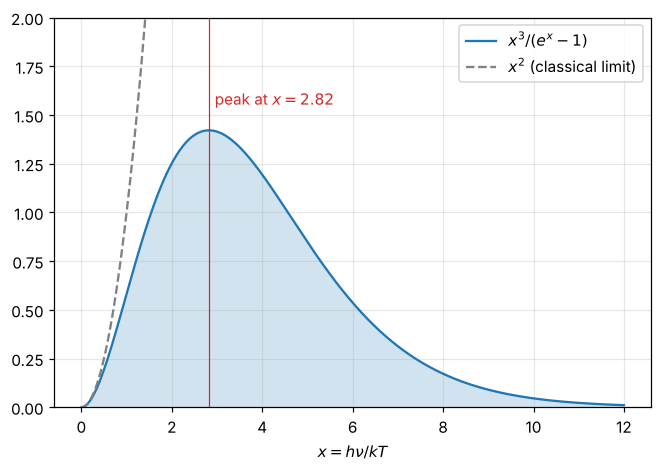

In [6]:
#| label: fig-planck-integrand
#| caption: "The integrand x³/(eˣ − 1) behind the Stefan–Boltzmann law (blue), its area π⁴/15, and the classical small-x approximation x² (dashed) whose integral diverges, which is the ultraviolet catastrophe in one picture."
xx = np.linspace(1e-3, 12, 500)
fig, ax = plt.subplots()
ax.plot(xx, xx**3 / np.expm1(xx), label=r"$x^3/(e^x-1)$")
ax.fill_between(xx, xx**3 / np.expm1(xx), alpha=0.2)
ax.plot(xx, xx**2, "--", color="gray", label=r"$x^2$ (classical limit)")
ax.axvline(2.821, color="tab:red", lw=0.8); ax.text(2.95, 1.55, "peak at $x = 2.82$", color="tab:red")
ax.set_ylim(0, 2.0); ax.set_xlabel("$x = h\\nu/kT$"); ax.legend(); plt.show()

### Exercises

1. Evaluate $\int_0^\infty x^5e^{-x^2}\,dx$ and $\Gamma(7/2)$.
2. Find the rms speed $\sqrt{\overline{v^2}}$ from the Maxwell distribution and confirm $\tfrac12m\overline{v^2} = \tfrac32kT$.
3. Use {eq}`eq-d-ball` to find the volume of the unit 4-ball, and the area of the unit sphere in 4 dimensions.
4. Evaluate $\int_0^\infty x^3/(e^x + 1)\,dx$ in terms of $\pi$.
5. Show that $\int_{-\infty}^\infty e^{-ax^2}\cos(kx)\,dx = \sqrt{\pi/a}\,e^{-k^2/4a}$.

:::{dropdown} Hints
1. Use {eq}`eq-gaussian-gamma` with $n = 5$; for $\Gamma(7/2)$ apply the recursion three times from $\Gamma(1/2)$.
2. You need $\int_0^\infty v^4e^{-av^2}dv = \Gamma(5/2)/2a^{5/2}$.
3. $\Gamma(3) = 2$; then $S_4 = dV_4/dr$ at $r = 1$.
4. Use the fermion formula with $s = 4$.
5. Write $\cos kx = \operatorname{Re}e^{ikx}$ and use {eq}`eq-gaussian-shift` with $b = ik$.
:::

:::{dropdown} Answers
1. $\Gamma(3)/2 = 1$; $\Gamma(7/2) = \tfrac52\cdot\tfrac32\cdot\tfrac12\sqrt\pi = \tfrac{15}{8}\sqrt\pi$.
2. $\overline{v^2} = 3kT/m$, so $v_{\text{rms}} = \sqrt{3kT/m}$ and $\tfrac12m\overline{v^2} = \tfrac32kT$.
3. $V_4 = \pi^2/2\approx4.93$; $S_4 = 2\pi^2\approx19.7$.
4. $(1 - 2^{-3})\cdot\pi^4/15 = 7\pi^4/120\approx5.68$.
5. $e^{(ik)^2/4a} = e^{-k^2/4a}$; the imaginary part vanishes because $\sin kx$ is odd.
:::

## Summary

- $\int e^{-ax^2} = \sqrt{\pi/a}$; differentiate in $a$ for moments, complete the square for linear terms.
- $\Gamma(n+1) = n!$, $\Gamma(\tfrac12) = \sqrt\pi$, and $\int_0^\infty x^ne^{-ax^2}dx = \Gamma(\tfrac{n+1}2)/2a^{(n+1)/2}$.
- A $d$-ball has volume $\pi^{d/2}r^d/\Gamma(d/2+1)$, nearly all of it near the surface when $d$ is large.
- Bose integrals are $\Gamma(s)\zeta(s)$; Fermi integrals carry an extra $1 - 2^{1-s}$.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.